In [3]:
# imports & data load
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("marketing_campaign.csv", sep="\t")
print(data.shape)
data.head()

(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
# missing values
print(data.isnull().sum()[data.isnull().sum() > 0])

data.dropna(inplace=True)
print(data.shape)

Income    24
dtype: int64
(2216, 29)


In [5]:
# feature engineering
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], dayfirst=True)

data["Age"] = 2025 - data["Year_Birth"]
data["Total_Children"] = data["Kidhome"] + data["Teenhome"]

spend_cols = ["MntWines", "MntFruits", "MntMeatProducts",
              "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
data["Total_Spending"] = data[spend_cols].sum(axis=1)

data["Customer_Since"] = (pd.Timestamp("today") - data["Dt_Customer"]).dt.days

data[["Age", "Total_Children", "Total_Spending", "Customer_Since"]].describe()

,Age,Total_Children,Total_Spending,Customer_Since
count,2216.000000,2216.000000,2216.000000,2216.000000
mean,56.179603,0.947202,607.075361,4875.521209
std,11.985554,0.749062,602.900476,202.434667
min,29.000000,0.000000,5.000000,4522.000000
25%,48.000000,0.000000,69.000000,4702.000000
50%,55.000000,1.000000,396.500000,4877.500000
75%,66.000000,1.000000,1048.000000,5051.000000
max,132.000000,3.000000,2525.000000,5221.000000


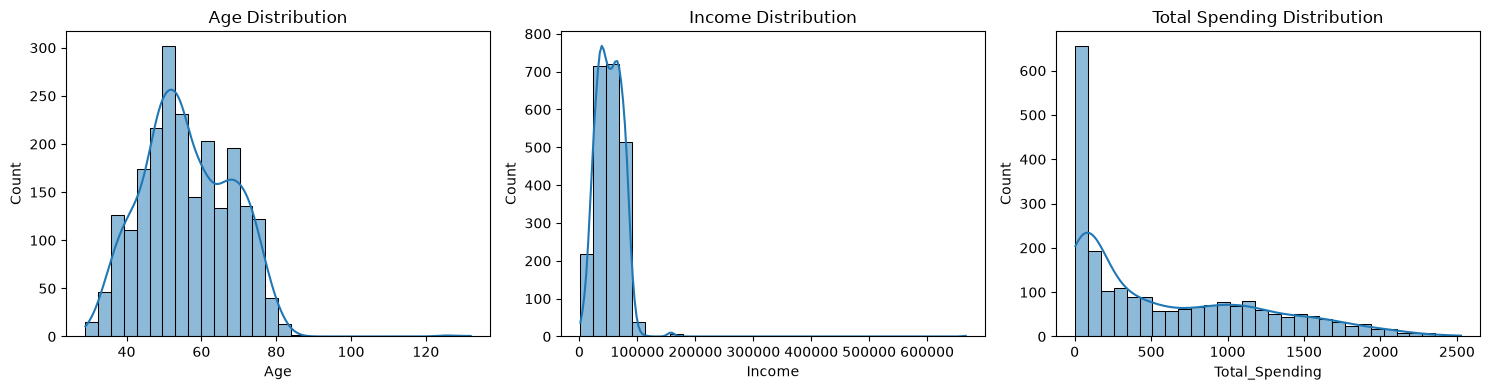

In [6]:
# eda - distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data["Age"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.histplot(data["Income"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Income Distribution")

sns.histplot(data["Total_Spending"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Total Spending Distribution")

plt.tight_layout()
plt.show()

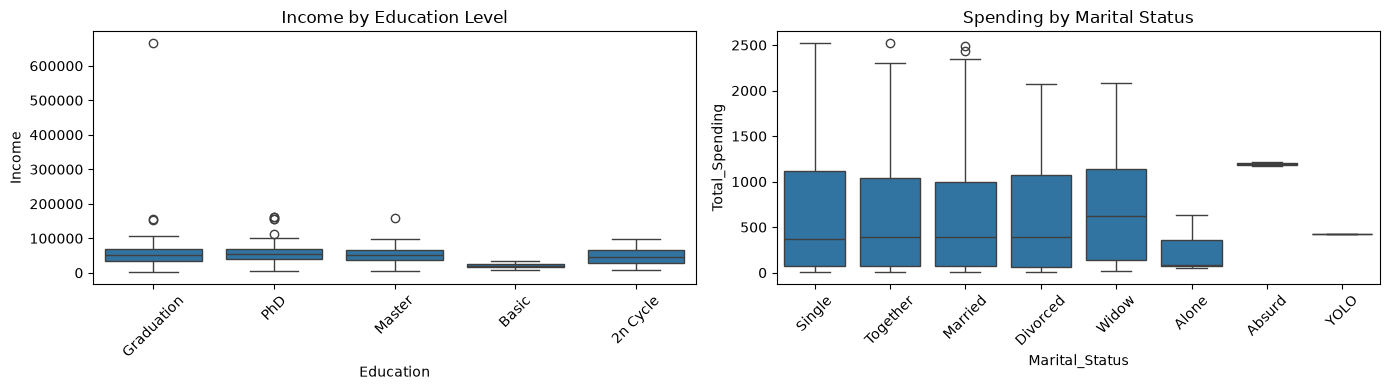

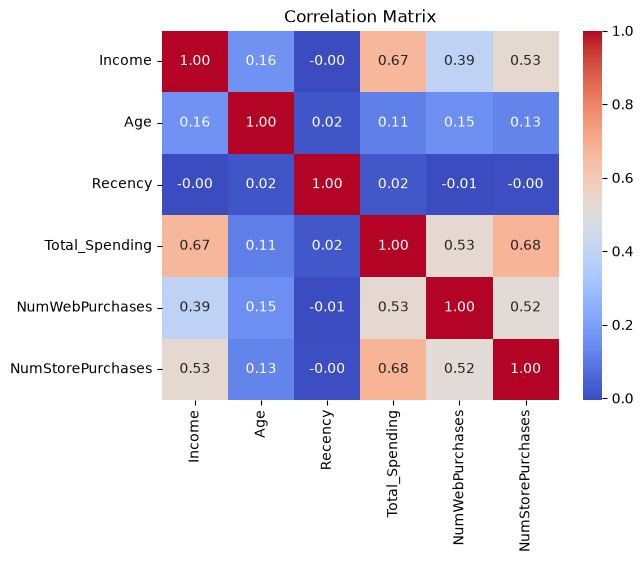

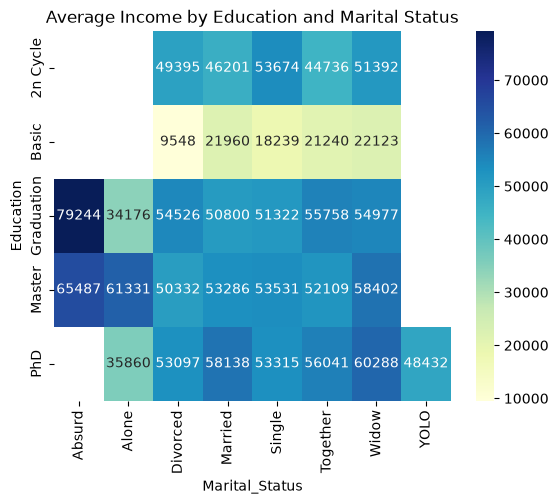

In [7]:
# eda - income & spending comparisons
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x="Education", y="Income", data=data, ax=axes[0])
axes[0].set_title("Income by Education Level")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(x="Marital_Status", y="Total_Spending", data=data, ax=axes[1])
axes[1].set_title("Spending by Marital Status")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# correlation
corr = data[["Income", "Age", "Recency", "Total_Spending",
             "NumWebPurchases", "NumStorePurchases"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

# pivot table
pivot_income = data.pivot_table(values="Income", index="Education",
                                columns="Marital_Status", aggfunc="mean")

sns.heatmap(pivot_income, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average Income by Education and Marital Status")
plt.show()

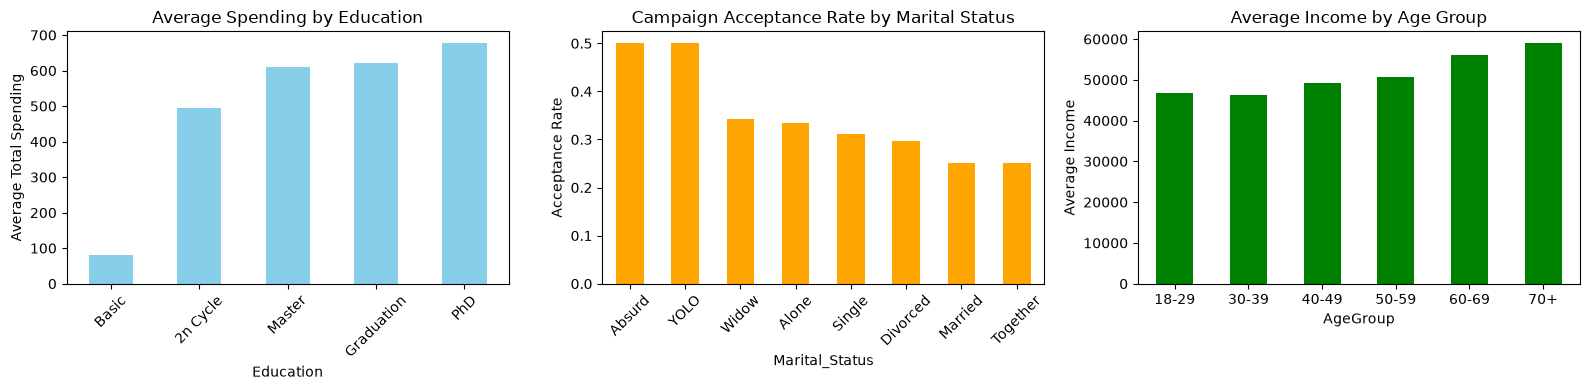

In [8]:
# group analysis
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# avg spending by education
group1 = data.groupby("Education")["Total_Spending"].mean().sort_values()
group1.plot(kind="bar", color="skyblue", ax=axes[0])
axes[0].set_title("Average Spending by Education")
axes[0].set_ylabel("Average Total Spending")
axes[0].tick_params(axis="x", rotation=45)

# campaign acceptance by marital status
campaigns = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
             "AcceptedCmp4", "AcceptedCmp5", "Response"]
data["AcceptedAny"] = (data[campaigns].sum(axis=1) > 0).astype(int)

group2 = data.groupby("Marital_Status")["AcceptedAny"].mean().sort_values(ascending=False)
group2.plot(kind="bar", color="orange", ax=axes[1])
axes[1].set_title("Campaign Acceptance Rate by Marital Status")
axes[1].set_ylabel("Acceptance Rate")
axes[1].tick_params(axis="x", rotation=45)

# avg income by age group
bins = [18, 30, 40, 50, 60, 70, 90]
labels = ["18-29", "30-39", "40-49", "50-59", "60-69", "70+"]
data["AgeGroup"] = pd.cut(data["Age"], bins=bins, labels=labels)

group3 = data.groupby("AgeGroup", observed=False)["Income"].mean()
group3.plot(kind="bar", color="green", ax=axes[2])
axes[2].set_title("Average Income by Age Group")
axes[2].set_ylabel("Average Income")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

k = 2: 0.3215
k = 3: 0.2645
k = 4: 0.1947
k = 5: 0.1916
k = 6: 0.1839
k = 7: 0.1850
k = 8: 0.1848
k = 9: 0.1849
Best k: 2


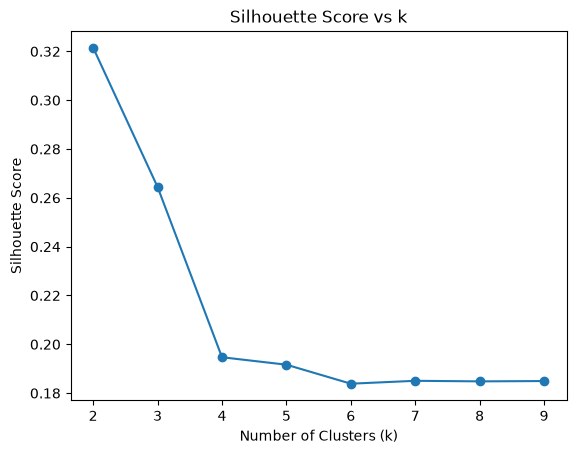

In [9]:
# scaling & choosing k with silhouette score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = ["Age", "Income", "Total_Spending",
            "NumWebPurchases", "NumStorePurchases",
            "NumWebVisitsMonth", "Recency"]

X = data[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

sil_scores = {}
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    sil_scores[k] = silhouette_score(X_scaled, labels)
    print(f"k = {k}: {sil_scores[k]:.4f}")

best_k = max(sil_scores, key=sil_scores.get)
print("Best k:", best_k)

plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o")
plt.title("Silhouette Score vs k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.show()

In [11]:
# final k-means with best k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
data["Cluster"] = kmeans.fit_predict(X_scaled)

print(data["Cluster"].value_counts())

cluster_summary = data.groupby("Cluster")[features].mean().round(1)
cluster_summary

Cluster
0    1158
1    1058
Name: count, dtype: int64


,Age,Income,Total_Spending,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth,Recency
Cluster,,,,,,,
0,54.1,35726.9,136.2,2.5,3.4,6.5,48.7
1,58.5,70329.1,1122.4,5.8,8.4,4.0,49.3


Components kept: 6
Variance explained: 0.961
k = 2: 0.3302
k = 3: 0.2712
k = 4: 0.2035
k = 5: 0.2002
k = 6: 0.1931
k = 7: 0.1909
k = 8: 0.1931
k = 9: 0.1935
Best k (PCA): 2

Without PCA: 0.3215
With PCA:    0.3302


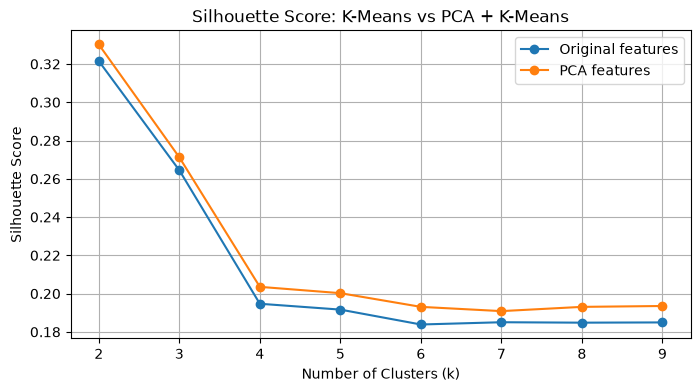

In [13]:
# pca + k-means
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Components kept:", X_pca.shape[1])
print("Variance explained:", round(pca.explained_variance_ratio_.sum(), 3))

sil_scores_pca = {}
for k in range(2, 10):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca)
    sil_scores_pca[k] = silhouette_score(X_pca, labels)
    print(f"k = {k}: {sil_scores_pca[k]:.4f}")

best_k_pca = max(sil_scores_pca, key=sil_scores_pca.get)
print("Best k (PCA):", best_k_pca)

print(f"\nWithout PCA: {sil_scores[best_k]:.4f}")
print(f"With PCA:    {sil_scores_pca[best_k_pca]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", label="Original features")
plt.plot(list(sil_scores_pca.keys()), list(sil_scores_pca.values()), marker="o", label="PCA features")
plt.title("Silhouette Score: K-Means vs PCA + K-Means")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.legend()
plt.grid(True)
plt.show()

PCA_Cluster
0    1156
1    1060
Name: count, dtype: int64


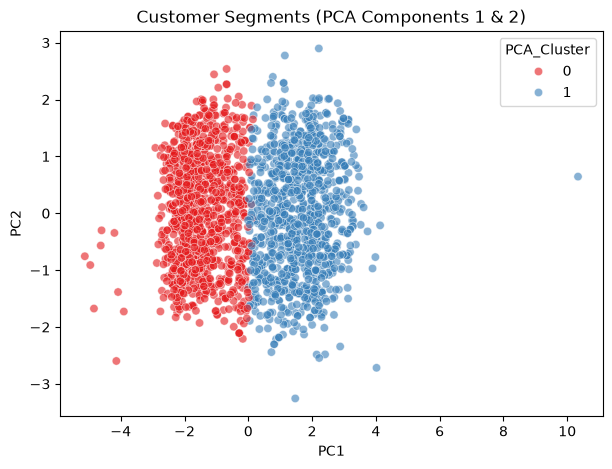

,Age,Income,Total_Spending,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth,Recency
PCA_Cluster,,,,,,,
Low-value,54.1,35692.4,135.9,2.5,3.4,6.5,48.7
High-value,58.5,70301.4,1120.9,5.8,8.4,4.0,49.3


In [14]:
# final segments with pca + k-means
pca_model = KMeans(n_clusters=best_k_pca, random_state=42, n_init=10)
data["PCA_Cluster"] = pca_model.fit_predict(X_pca)

print(data["PCA_Cluster"].value_counts())

pca_summary = data.groupby("PCA_Cluster")[features].mean().round(1)
pca_summary

# 2d view of the clusters
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=data["PCA_Cluster"],
                palette="Set1", alpha=0.6)
plt.title("Customer Segments (PCA Components 1 & 2)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# segment profile
segment_names = {pca_summary["Total_Spending"].idxmax(): "High-value",
                 pca_summary["Total_Spending"].idxmin(): "Low-value"}
pca_summary.index = pca_summary.index.map(segment_names)
pca_summary

Segment,High-value,Low-value
Customers,1060.00,1156.00
Revenue,1188150.00,157129.00
Avg_Spend,1120.90,135.92
Campaign_Response,0.39,0.16
Deal_Purchases,2.31,2.34
Web_Visits,3.98,6.54
Web_Purchases,5.81,2.51
Store_Purchases,8.38,3.44
Catalog_Purchases,4.76,0.76
Customer_Share_%,47.83,52.17


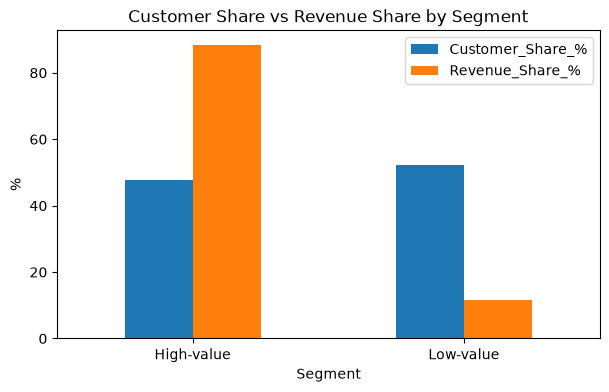

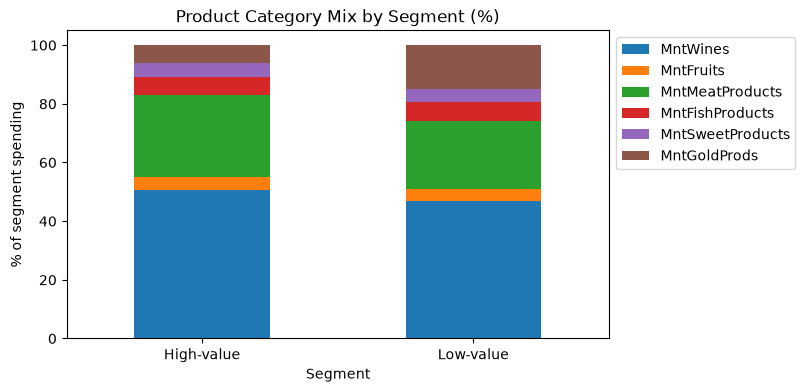

In [15]:
# business view of segments
data["Segment"] = data["PCA_Cluster"].map(segment_names)

biz = data.groupby("Segment").agg(
    Customers=("ID", "count"),
    Revenue=("Total_Spending", "sum"),
    Avg_Spend=("Total_Spending", "mean"),
    Campaign_Response=("AcceptedAny", "mean"),
    Deal_Purchases=("NumDealsPurchases", "mean"),
    Web_Visits=("NumWebVisitsMonth", "mean"),
    Web_Purchases=("NumWebPurchases", "mean"),
    Store_Purchases=("NumStorePurchases", "mean"),
    Catalog_Purchases=("NumCatalogPurchases", "mean"))

biz["Customer_Share_%"] = biz["Customers"] / biz["Customers"].sum() * 100
biz["Revenue_Share_%"] = biz["Revenue"] / biz["Revenue"].sum() * 100
display(biz.round(2).T)

# customer share vs revenue share
biz[["Customer_Share_%", "Revenue_Share_%"]].plot(kind="bar", figsize=(7, 4))
plt.title("Customer Share vs Revenue Share by Segment")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.show()

# product mix by segment
cat_share = data.groupby("Segment")[spend_cols].sum()
cat_share = cat_share.div(cat_share.sum(axis=1), axis=0) * 100
cat_share.plot(kind="bar", stacked=True, figsize=(7, 4))
plt.title("Product Category Mix by Segment (%)")
plt.ylabel("% of segment spending")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.show()